In [130]:
import torch
from torch import nn
import torch.nn.functional as F

import torchvision
from torchvision.transforms import ToTensor

# Import matplotlib for visualization
import matplotlib.pyplot as plt

# Check versions
# Note: your PyTorch version shouldn't be lower than 1.10.0 and torchvision version shouldn't be lower than 0.11
print(f"PyTorch version: {torch.__version__}\ntorchvision version: {torchvision.__version__}")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

PyTorch version: 2.11.0
torchvision version: 0.26.0


In [131]:
def normalize(t, mode="minmax"):
  """Map any conv output into [0, 1] so imshow can display it.

  minmax: (t - min) / (max - min) -> always spans [0, 1], stretches contrast
          but is relative per tensor, so brightness is not comparable.
  clamp:  cut values outside [0, 1] -> keeps absolute brightness, loses detail
          in the clipped regions.
  """
  t = t.detach().float()
  if mode == "clamp":
    return t.clamp(0, 1)
  return (t - t.min()) / (t.max() - t.min() + 1e-8)

def show(t, title="", mode="minmax"):
  """t: [C, H, W] or [1, C, H, W] -> imshow expects [H, W, C]"""
  if t.dim() == 4:
    t = t[0]
  if t.shape[0] == 1:
    plt.imshow(normalize(t[0], mode).numpy(), cmap="gray")
    plt.title(title)
    plt.axis("off")
    plt.show()
    return
  plt.imshow(normalize(t, mode).permute(1, 2, 0).numpy())
  plt.title(title)
  plt.axis("off")
  plt.show()

def show_channels(t, title="", mode="minmax"):
  """Plot per-channel response instead of collapsing them visually."""
  if t.dim() == 4:
    t = t[0]
  C = t.shape[0]
  names = ["R", "G", "B"] if C == 3 else [str(i) for i in range(C)]
  # squeeze=False keeps ax a 2D array even when C == 1
  fig, ax = plt.subplots(1, C, figsize=(4 * C, 4), squeeze=False)
  for c in range(C):
    ax[0][c].imshow(normalize(t[c].abs(), mode).numpy(), cmap="gray")
    ax[0][c].set_title(f"{title} {names[c]}")
    ax[0][c].axis("off")
  plt.show()


In [132]:
def load_image(path, w=64, h=64, add_batch=True):
    transform = transforms.Compose([
        transforms.Resize((h, w)),  # height, width
        transforms.ToTensor(), #ToTensor() 1. [H, W, C] → [C, H, W], 2. Divides by 255 → float32 in [0, 1]
    ])
    img = Image.open(path).convert("RGB")
    x = transform(img)  # [3, H, W]
    if add_batch:
        x = x.unsqueeze(0)  # [1, 3, H, W]
    return x

In [133]:
from PIL import Image
from torchvision import transforms
from pathlib import Path
import numpy as np

image1_path = "../data/images/1.jpeg"  #620x920
image = load_image(image1_path, 1020, 768)
print(image.shape)


torch.Size([1, 3, 768, 1020])


In [134]:
import numpy as np

def conv2d_manual(kernel, image, padding=0, stride=1):
  # kernel: [3, 3]
  # image: [1, 3, H, W]
  img = image[0]  # [3, H, W]
  C, H, W = img.shape
  kH, kW = kernel.shape

  if padding > 0:
    img = torch.nn.functional.pad(img, (padding, padding, padding, padding), mode="constant")
  _, Hp, Wp = img.shape

  outH = (Hp - kH) // stride + 1
  outW = (Wp - kW) // stride + 1
  out = torch.zeros((C, outH, outW), dtype=torch.float32)

  # Apply convolution
  for i in range(outH):
    for j in range(outW):
      h0 = i * stride
      w0 = j * stride
      target = img[:, h0:h0+kH, w0:w0+kW]      # [3, 3, 3] 3 channels
      # out[:, i, j] = torch.sum(target * kernel[None, :, :])
      out[:, i, j] = torch.sum(target * kernel[None, :, :], dim=(1, 2))

  return out

def conv2d_torch(kernel, image, padding=0, stride=1):
  # Standard conv: sums across input channels -> one output map [1, 1, H, W]
  C = image.shape[1]
  weight = kernel.unsqueeze(0).unsqueeze(0)  # [1, 1, 3, 3]
  weight = weight.repeat(1, C, 1, 1)         # [1, 3, 3, 3]

  return F.conv2d(image, weight, padding=padding, stride=stride)



In [137]:
img_dir = Path("../data/private")
images = []
for img_path in img_dir.glob("*.jpg"):
  image = load_image(img_path, 1020, 768)
  images.append(image)

edge_kernel = torch.tensor([
    [0, 1, 0],
    [1, -4, 1],
    [0, 1, 0]
], dtype=torch.float32)
sharpen_kernel = torch.tensor([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
], dtype=torch.float32)
strong_edge_kernel = torch.tensor([
    [-1, -2, -1],
    [0, 0, 0],
    [1, 2, 1]
], dtype=torch.float32)

# Rule of thumb: sum(kernel) == 1 -> brightness/color preserved
#                sum(kernel) == 0 -> edges only, looks gray

identity_kernel = torch.tensor([
    [0, 0, 0],
    [0, 1, 0],
    [0, 0, 0]
], dtype=torch.float32)

box_blur_kernel = torch.ones((3, 3), dtype=torch.float32) / 9.0

gaussian_kernel = torch.tensor([
    [1, 2, 1],
    [2, 4, 2],
    [1, 2, 1]
], dtype=torch.float32) / 16.0

emboss_kernel = torch.tensor([
    [-2, -1, 0],
    [-1,  1, 1],
    [ 0,  1, 2]
], dtype=torch.float32)

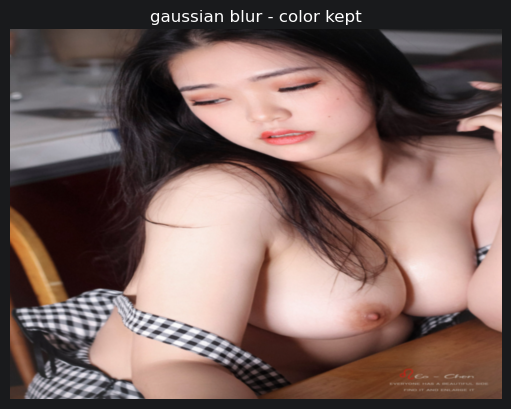

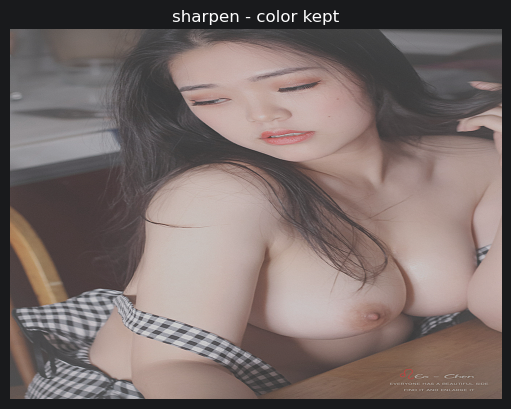

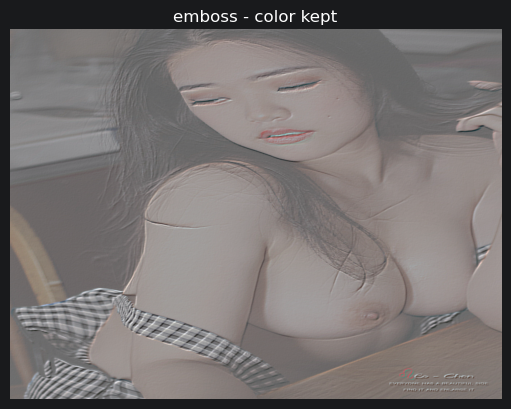

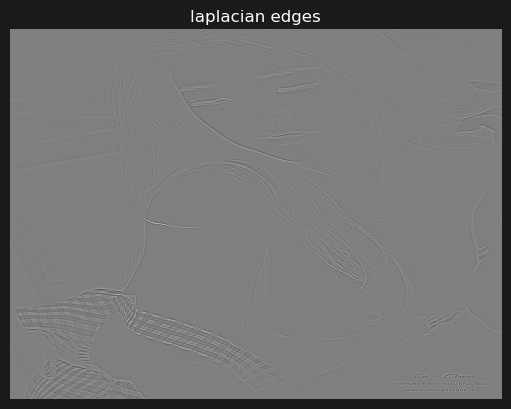

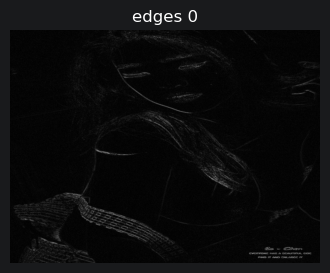

In [138]:
# Color-preserving filters (sum == 1)
show(conv2d_manual(gaussian_kernel, images[0]), "gaussian blur - color kept")
show(conv2d_manual(sharpen_kernel, images[0]), "sharpen - color kept")
show(conv2d_manual(emboss_kernel, images[0]), "emboss - color kept")

# Edge filters (sum == 0) - color is intentionally removed
edge = conv2d_torch(edge_kernel, images[0])
show(edge, "laplacian edges")
show_channels(edge, "edges")
